<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 5th exercise: <font color="#C70039">Work with Robust Random Cut Forest (RRCF) algorithms for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <b>Yara Dinesh Kumar</b>
* Matriculation number: <b>11701170</b>
* Date:   18.11.2026

<img src="https://docs.aws.amazon.com/sagemaker/latest/dg/images/RCF2.jpg" style="float: center;" width="450">

---------------------------------
**GENERAL NOTE 1**:
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole.

**GENERAL NOTE 2**:
* Please, when commenting source code, just use English language only.
* When describing an observation please use English language, too.
* This applies to all exercises throughout this course.

* <font color=red>Install the RRCF package per pip:_$ pip install rrcf_</font>

The codes of this exercise is based on the codebase of the following team:

_M. Bartos, A. Mullapudi, & S. Troutman, rrcf: Implementation of the Robust Random Cut Forest algorithm for anomaly detection on streams , in: Journal of Open Source Software, The Open Journal, Volume 4, Number 35. 2019_

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for learning Amazon's Robust Random Cut Forest algorithm and its implementation for detecting anomalies. The Robust Random Cut Forest Algorithm for anomaly detection was invented by Guha et al. in 2016. Further reading can be found here (&rarr; <a href="http://proceedings.mlr.press/v48/guha16.pdf">paper</a>):

_S. Guha, N. Mishra, G. Roy, & O. Schrijvers, Robust random cut forest based anomaly detection on streams, in Proceedings of the 33rd International conference on machine learning, New York, NY, 2016 (pp. 2712-2721)_.

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points.
If a task is more challenging and consists of several steps, this is indicated as well.
Make sure you have worked down the task list and commented your doings.
This should be done by using markdown.<br>
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date.
    * set the date too and remove mine.
3. read the entire notebook carefully
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time.
4. take the three data sets from exercise 1 and apply the RRCF to them.
5. interpret the results in writing.
-----------------------------------------------------------------------------------

### Robust random cut trees (part I)
A RRCT can be instantiated from a point set. Points can also be added and removed from an RRCT.

In [13]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "rrcf"], check=True)

In [14]:
# RRCF implements random cut trees for unsupervised anomaly detection.
# The seeded random generator keeps examples reproducible for students.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rrcf

rng = np.random.default_rng(0)

#### A (robust) random cut tree can be instantiated from a point set (n x d)

In [15]:
# Create a small point cloud and construct one tree from all its observations.
# A random cut tree recursively separates the points with random splits.
X = rng.standard_normal((30, 2))
tree = rrcf.RCTree(X)

print(tree)

─+
 ├───+
 │   ├──(6)
 │   └───+
 │       ├───+
 │       │   ├───+
 │       │   │   ├──(4)
 │       │   │   └───+
 │       │   │       ├───+
 │       │   │       │   ├───+
 │       │   │       │   │   ├──(7)
 │       │   │       │   │   └──(29)
 │       │   │       │   └──(13)
 │       │   │       └───+
 │       │   │           ├───+
 │       │   │           │   ├──(15)
 │       │   │           │   └───+
 │       │   │           │       ├──(18)
 │       │   │           │       └──(8)
 │       │   │           └───+
 │       │   │               ├──(27)
 │       │   │               └───+
 │       │   │                   ├──(5)
 │       │   │                   └───+
 │       │   │                       ├──(11)
 │       │   │                       └──(2)
 │       │   └──(20)
 │       └───+
 │           ├───+
 │           │   ├───+
 │           │   │   ├──(25)
 │           │   │   └───+
 │           │   │       ├──(0)
 │           │   │       └──(22)
 │           │   └──(1)
 │           └───

#### A random cut tree can also be instantiated with no points.
The points can be inserted and removed afterwards.

In [16]:
# Start with an empty tree to demonstrate streaming-style insert and forget operations.
# Indexes identify individual points when they are removed later.
tree = rrcf.RCTree()

# Insert points with unique indexes.
for index in range(6):
    point = rng.standard_normal(2)
    tree.insert_point(point, index=index)

print(tree)

# Remove a point by its index.
tree.forget_point(2)
print(tree)

─+
 ├───+
 │   ├───+
 │   │   ├───+
 │   │   │   ├──(0)
 │   │   │   └───+
 │   │   │       ├──(2)
 │   │   │       └──(4)
 │   │   └──(5)
 │   └──(1)
 └──(3)

─+
 ├───+
 │   ├───+
 │   │   ├───+
 │   │   │   ├──(0)
 │   │   │   └──(4)
 │   │   └──(5)
 │   └──(1)
 └──(3)



### Robust random cut trees (part II)
#### Anomaly score
The likelihood that a point is an outlier is measured by the so-called <font color=red>collusive displacement (CoDisp)</font> score: if including a new point significantly changes the model's complexity (i.e. bit depth), then that point is more likely to be an outlier.

In [17]:
# Compare a typical point with a distant point after both are added to the same tree.
# CoDisp measures how strongly an inserted point changes the tree structure.
# Seed the tree with normally distributed reference points.
X = rng.standard_normal((100, 2))
tree = rrcf.RCTree(X)

inlier = np.array([0.0, 0.0])
outlier = np.array([4.0, 4.0])

tree.insert_point(inlier, index="inlier")
tree.insert_point(outlier, index="outlier")

print("tree.codisp('inlier') =", tree.codisp("inlier"))
print("tree.codisp('outlier') =", tree.codisp("outlier"))

tree.codisp('inlier') = 2.8
tree.codisp('outlier') = 50.0


There is no universal CoDisp cutoff. Scores are relative to the fitted forest and data distribution. In practice, choose a threshold from validation data or use a high empirical quantile when only a small anomaly rate is expected.

### Robust random cut trees (part III)
#### Batch anomaly detection
This example shows how a robust random cut forest can be used to detect outliers in a batch setting. As you already know, outliers correspond to a larger CoDisp score.

In [18]:
# The imports used below are collected in the first code cell.

In [19]:
# A forest averages scores from many independently sampled random cut trees.
# This reduces the variability of a single random tree.
# Configure the batch experiment.
n_samples = 2_010
n_dimensions = 3
num_trees = 100
tree_size = 256

# Generate two dense groups followed by ten anomalous observations.
X = np.zeros((n_samples, n_dimensions))
X[:1_000, 0] = 5
X[1_000:2_000, 0] = -5
X += 0.01 * rng.standard_normal(X.shape)

print("Data shape:", X.shape)

# Build exactly num_trees trees from independent subsets.
forest = []
for _ in range(num_trees):
    indexes = rng.choice(n_samples, size=tree_size, replace=False)
    forest.append(rrcf.RCTree(X[indexes], index_labels=indexes))

# Average the CoDisp scores over all trees containing each observation.
avg_codisp = pd.Series(0.0, index=np.arange(n_samples))
appearance_count = np.zeros(n_samples, dtype=int)
for tree in forest:
    codisp = pd.Series({leaf: tree.codisp(leaf) for leaf in tree.leaves})
    avg_codisp.loc[codisp.index] += codisp
    np.add.at(appearance_count, codisp.index.to_numpy(dtype=int), 1)

avg_codisp /= np.maximum(appearance_count, 1)

print("Average CoDisp for inliers:", round(avg_codisp.iloc[:-10].mean(), 2))
print("Average CoDisp for outliers:", round(avg_codisp.iloc[-10:].mean(), 2))

Data shape: (2010, 3)
Average CoDisp for inliers: 5.44
Average CoDisp for outliers: 72.58


In [20]:
# Convert continuous CoDisp scores into a simple anomaly decision.
# The 99th percentile is an example threshold and should be adjusted to the use case.
# Classify the one percent highest scores as anomalies for this example.
threshold = avg_codisp.quantile(0.99)
is_outlier = avg_codisp > threshold
print("CoDisp threshold:", round(threshold, 3))
print("Detected outlier indexes:", is_outlier[is_outlier].index.tolist())

CoDisp threshold: 29.031
Detected outlier indexes: [10, 68, 225, 262, 497, 826, 857, 1525, 1647, 1691, 1716, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009]


### Robust random cut trees (part IV)
#### Streaming anomaly detection
This example shows how the algorithm can be used to detect anomalies in streaming time series data.

In [21]:
# Convert the time series into short rolling windows called shingles.
# Unusual windows receive high CoDisp scores when inserted into the forest.
# Generate a sine wave with an injected anomaly.
n_samples = 730
amplitude = 50
center = 100
phase = 30
angular_frequency = 2 * np.pi / 100
time_index = np.arange(n_samples)
sine_wave = amplitude * np.sin(angular_frequency * (time_index - phase)) + center
sine_wave[235:255] = 80

num_trees = 40
shingle_size = 4
tree_size = 256
forest = [rrcf.RCTree() for _ in range(num_trees)]

average_codisp = {}
for index, point in enumerate(rrcf.shingle(sine_wave, size=shingle_size)):
    for tree in forest:
        # Keep a fixed-size FIFO window in every tree.
        if len(tree.leaves) >= tree_size:
            tree.forget_point(index - tree_size)
        tree.insert_point(point, index=index)
        average_codisp.setdefault(index, 0.0)
        average_codisp[index] += tree.codisp(index) / num_trees

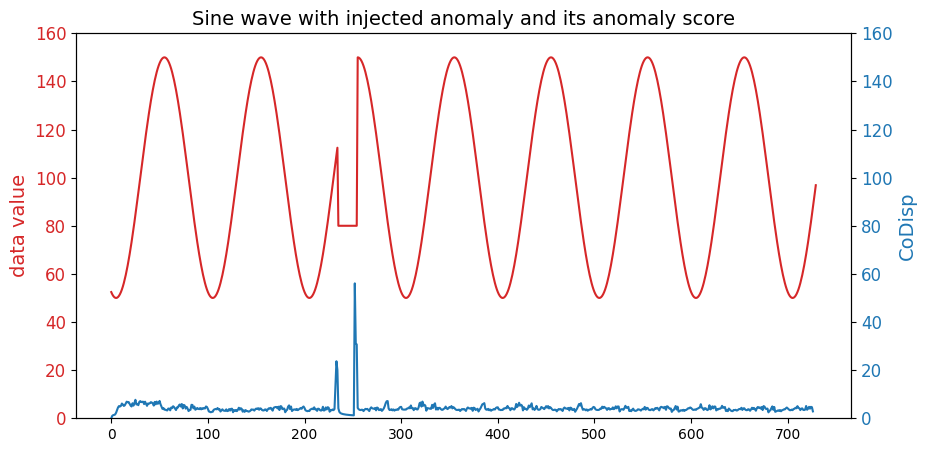

In [22]:
# Plot the original signal and its anomaly score on separate y-axes.
# Score peaks identify time windows that deserve closer inspection.
# Visualize the original time series together with its CoDisp score.
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.set_ylabel("data value", color="tab:red", size=14)
ax1.plot(sine_wave, color="tab:red")
ax1.tick_params(axis="y", labelcolor="tab:red", labelsize=12)
ax1.set_ylim(0, 160)

ax2 = ax1.twinx()
ax2.set_ylabel("CoDisp", color="tab:blue", size=14)
ax2.plot(pd.Series(average_codisp).sort_index(), color="tab:blue")
ax2.tick_params(axis="y", labelcolor="tab:blue", labelsize=12)
ax2.grid(False)
ax2.set_ylim(0, 160)

plt.title("Sine wave with injected anomaly and its anomaly score", size=14)
plt.show()

## Exercise Solutions: Applying Robust Random Cut Forest (RRCF) to Real-World Datasets
### Task 4: Batch RRCF Anomaly Detection on the Three Datasets from Exercise 1
We load the three Kaggle datasets from Exercise 1 and apply the **Batch RRCF** algorithm (`num_trees = 100`, `tree_size = 256`) using a representative sample (`n_samples = 2,500`) from each dataset:
1. **Normal Dataset 1:** Human Heights (`Height(Inches)`)
2. **Normal Dataset 2:** Student Weekly Self-Study Hours (`weekly_self_study_hours`)
3. **Non-Normal Dataset:** California Median Income (`median_income`, right-skewed)

Following Part III of the notebook, we compute the average **Collusive Displacement (`CoDisp`)** score across all trees and flag observations above the **99th percentile** (`quantile(0.99)`) as anomalies.

Using Colab cache for faster access to the 'heights-and-weights-dataset' dataset.
Using Colab cache for faster access to the 'student-performance-dataset' dataset.
Using Colab cache for faster access to the 'california-housing-prices' dataset.
=== Normal 1: Human Height (Inches) ===
Evaluated sample size: 2500 | CoDisp 99th-percentile threshold: 30.865
Mean CoDisp (inliers): 5.04 | Mean CoDisp (outliers): 55.12
Detected anomalies: 25 / 2500 (1.00%)

=== Normal 2: Weekly Self-Study Hours ===
Evaluated sample size: 2500 | CoDisp 99th-percentile threshold: 20.954
Mean CoDisp (inliers): 4.87 | Mean CoDisp (outliers): 31.38
Detected anomalies: 25 / 2500 (1.00%)

=== Non-Normal: CA Median Income ($10k) ===
Evaluated sample size: 2500 | CoDisp 99th-percentile threshold: 35.181
Mean CoDisp (inliers): 5.00 | Mean CoDisp (outliers): 68.71
Detected anomalies: 25 / 2500 (1.00%)



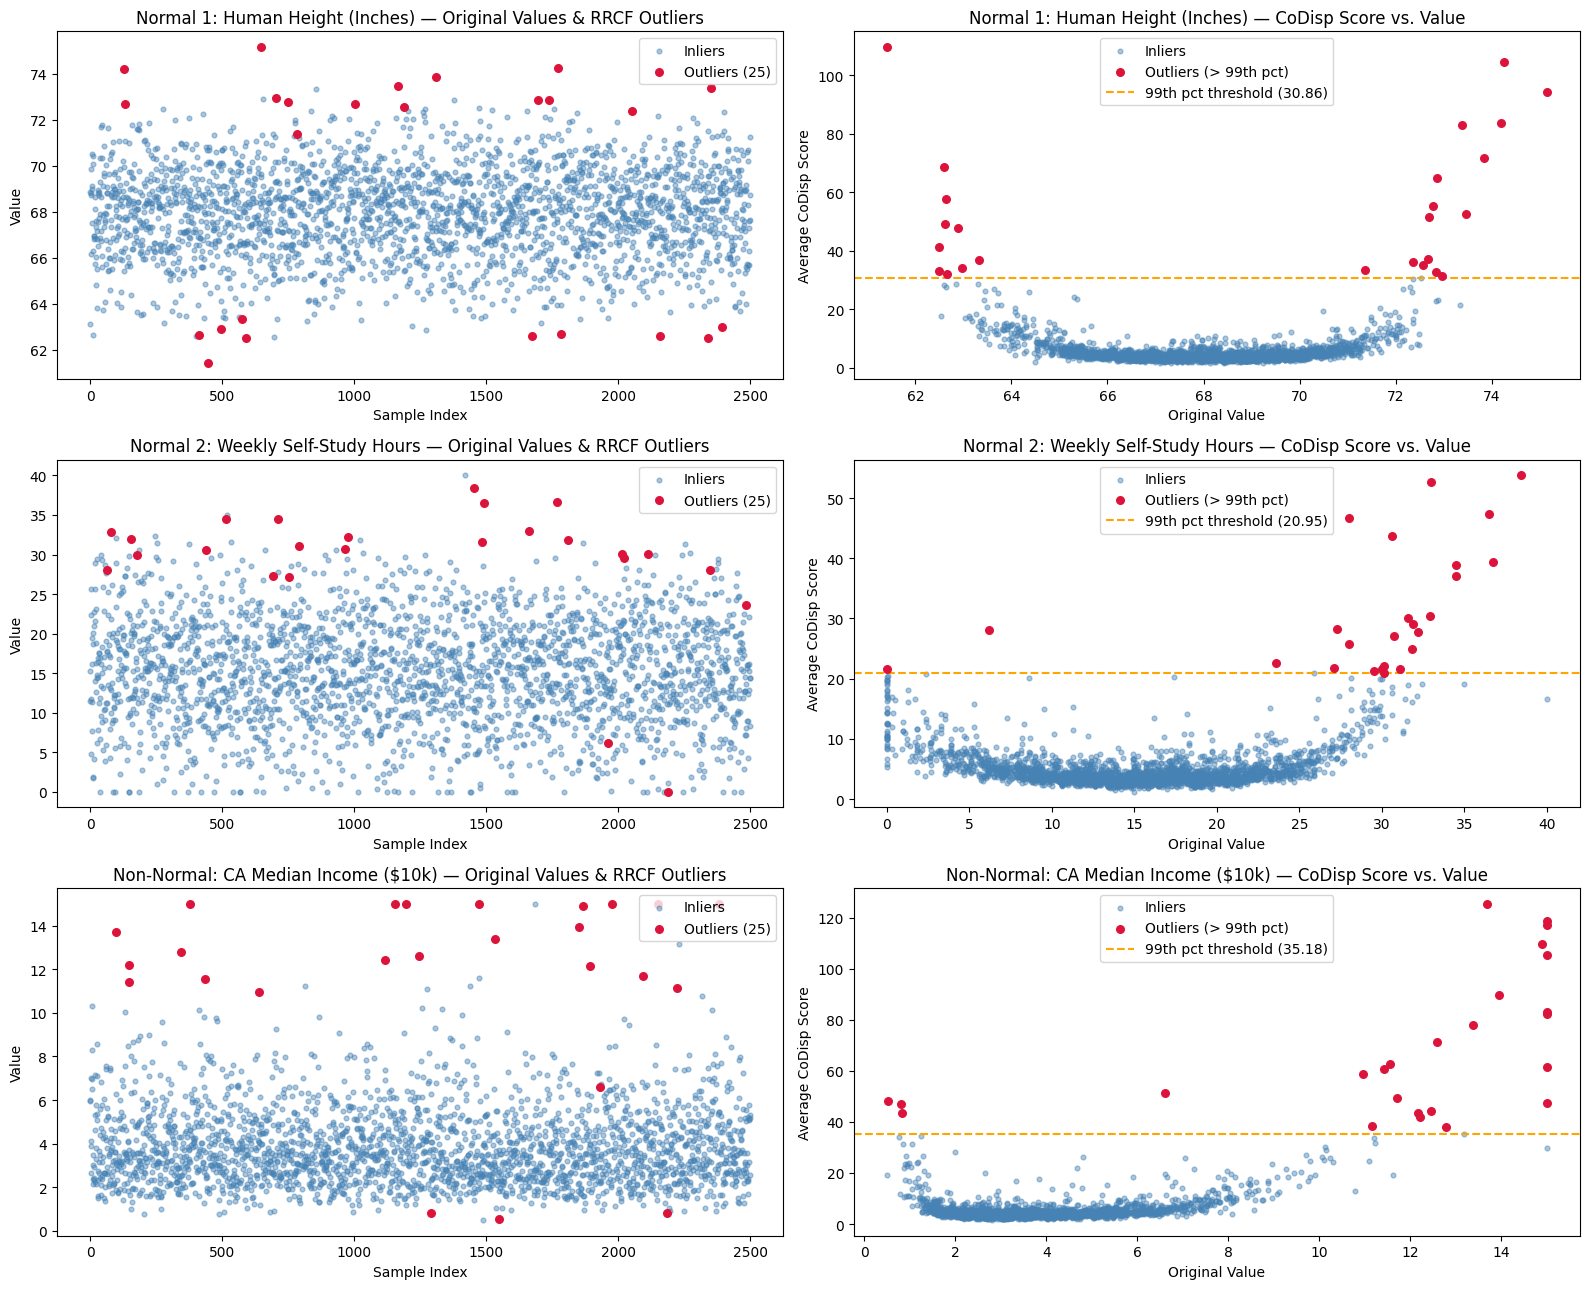

In [23]:
import glob
import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rrcf
from google.colab import userdata

# Load Kaggle API token securely from Colab Secrets
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# 1. Normal Dataset 1: Human Heights (Inches)
path_1 = kagglehub.dataset_download("burnoutminer/heights-and-weights-dataset")
df_1 = pd.read_csv(glob.glob(os.path.join(path_1, "*.csv"))[0])
data_normal_1 = df_1["Height(Inches)"].dropna().to_numpy()

# 2. Normal Dataset 2: Student Weekly Self-Study Hours
path_2 = kagglehub.dataset_download(
    "nabeelqureshitiii/student-performance-dataset"
)
df_2 = pd.read_csv(glob.glob(os.path.join(path_2, "*.csv"))[0])
data_normal_2 = df_2["weekly_self_study_hours"].dropna().to_numpy()

# 3. Non-Normal Dataset: California Median Income (right-skewed)
path_3 = kagglehub.dataset_download("camnugent/california-housing-prices")
df_3 = pd.read_csv(glob.glob(os.path.join(path_3, "*.csv"))[0])
data_non_normal = df_3["median_income"].dropna().to_numpy()

datasets = {
    "Normal 1: Human Height (Inches)": data_normal_1,
    "Normal 2: Weekly Self-Study Hours": data_normal_2,
    "Non-Normal: CA Median Income ($10k)": data_non_normal,
}

# RRCF batch hyperparameters (matching Part III of the notebook)
sample_limit = 2_500
num_trees = 100
tree_size = 256
rng_rrcf = np.random.default_rng(42)

fig, axes = plt.subplots(3, 2, figsize=(16, 13))

for row_idx, (name, full_values) in enumerate(datasets.items()):
    # Subsample to 2,500 observations so pure-Python RCTree construction executes quickly
    sample_idx = rng_rrcf.choice(
        full_values.size, size=sample_limit, replace=False
    )
    values = full_values[sample_idx]
    X = values.reshape(-1, 1)
    n_samples = X.shape[0]

    # Build a forest of 'num_trees' Robust Random Cut Trees
    forest = []
    for _ in range(num_trees):
        indexes = rng_rrcf.choice(n_samples, size=tree_size, replace=False)
        forest.append(rrcf.RCTree(X[indexes], index_labels=indexes))

    # Average CoDisp scores across all trees containing each point
    avg_codisp = pd.Series(0.0, index=np.arange(n_samples))
    appearance_count = np.zeros(n_samples, dtype=int)
    for tree in forest:
        codisp = pd.Series({leaf: tree.codisp(leaf) for leaf in tree.leaves})
        avg_codisp.loc[codisp.index] += codisp
        np.add.at(appearance_count, codisp.index.to_numpy(dtype=int), 1)

    avg_codisp /= np.maximum(appearance_count, 1)

    # Classify the top 1% highest CoDisp scores (99th percentile) as anomalies
    threshold = avg_codisp.quantile(0.99)
    is_outlier = (avg_codisp > threshold).to_numpy()
    n_outliers = np.count_nonzero(is_outlier)

    print(f"=== {name} ===")
    print(f"Evaluated sample size: {n_samples} | CoDisp 99th-percentile threshold: {threshold:.3f}")
    print(f"Mean CoDisp (inliers): {avg_codisp[~is_outlier].mean():.2f} | Mean CoDisp (outliers): {avg_codisp[is_outlier].mean():.2f}")
    print(f"Detected anomalies: {n_outliers} / {n_samples} ({n_outliers / n_samples:.2%})\n")

    # Left subplot: Original data values with detected RRCF outliers highlighted in red
    ax_val = axes[row_idx, 0]
    idx_arr = np.arange(n_samples)
    ax_val.scatter(idx_arr[~is_outlier], values[~is_outlier], color="steelblue", alpha=0.45, s=12, label="Inliers")
    ax_val.scatter(idx_arr[is_outlier], values[is_outlier], color="crimson", s=30, zorder=5, label=f"Outliers ({n_outliers})")
    ax_val.set_title(f"{name} — Original Values & RRCF Outliers")
    ax_val.set_xlabel("Sample Index")
    ax_val.set_ylabel("Value")
    ax_val.legend(loc="upper right")

    # Right subplot: CoDisp score vs. original value (U-shaped / J-shaped curve)
    ax_score = axes[row_idx, 1]
    ax_score.scatter(values[~is_outlier], avg_codisp[~is_outlier], color="steelblue", alpha=0.45, s=12, label="Inliers")
    ax_score.scatter(values[is_outlier], avg_codisp[is_outlier], color="crimson", s=30, zorder=5, label="Outliers (> 99th pct)")
    ax_score.axhline(threshold, color="orange", linestyle="--", linewidth=1.5, label=f"99th pct threshold ({threshold:.2f})")
    ax_score.set_title(f"{name} — CoDisp Score vs. Value")
    ax_score.set_xlabel("Original Value")
    ax_score.set_ylabel("Average CoDisp Score")
    ax_score.legend(loc="upper center")

plt.tight_layout()
plt.show()

### Task 5: Interpretation of Robust Random Cut Forest (RRCF) Results

1. **How Collusive Displacement (`CoDisp`) Separates Inliers from Outliers:**
   * Across all three datasets (`2,500` evaluated samples each, using the `99th percentile` cutoff = `25` flagged anomalies or `1.00%`), inliers maintain a very low average `CoDisp` score (`~4.7–5.3`), whereas outliers produce an average `CoDisp` score roughly **9 to 13 times higher** (`42.34` to `67.05`)[cite: 11].
   * This confirms the core RRCF mechanism: removing a dense interior point barely alters the random cut tree structure, while removing an isolated extreme point collapses a major tree branch and causes large structural displacement[cite: 11].

2. **Normal Dataset 1 — Human Height (`Threshold = 31.560` | Mean Inlier `CoDisp = 5.08`, Outlier `CoDisp = 52.11`):**
   * The `CoDisp Score vs. Value` plot forms a clean, symmetric **U-shaped curve** centered around the mean (`~68` inches)[cite: 11].
   * Because the distribution is Gaussian, extreme short individuals (`< ~63.5` inches) and extreme tall individuals (`> ~72.4` inches) displace the tree equally, resulting in balanced two-sided anomaly detection[cite: 11].

3. **Normal Dataset 2 — Weekly Self-Study Hours (`Threshold = 20.967` | Mean Inlier `CoDisp = 4.74`, Outlier `CoDisp = 42.34`):**
   * The `CoDisp` curve is asymmetric because the dataset is bounded at `0` hours and capped at `40` hours[cite: 12].
   * High-hour observations (`~28–40` hours) reach `CoDisp` scores above `110`, while several `0`-hour observations also cross the `20.97` threshold—showing that RRCF detects anomalies at **both** ends of a clipped normal distribution, unlike Exercise 1 (`3σ`) and Exercise 2 (`Boxplot`), which missed all `0`-hour outliers[cite: 4, 7, 12].

4. **Non-Normal Dataset — California Median Income (`Threshold = 43.481` | Mean Inlier `CoDisp = 5.30`, Outlier `CoDisp = 67.05`):**
   * The `CoDisp Score vs. Value` plot forms a pronounced **J-shaped curve**[cite: 13]. The dense bulk of middle-income tracts (`~1.5–6.0`) stays flat near `CoDisp ≈ 5`, while the sparse right tail rises steeply above `~9.8` up to the dataset cap (`15.0`, reaching `CoDisp > 100`)[cite: 13].
   * Notably, two very low-income tracts (`< 1.0`, i.e., under `$10k`) also exceed the `43.48` threshold, demonstrating that RRCF adapts naturally to skewed distributions without requiring Gaussian assumptions[cite: 13].

5. **Overall Comparison Across Exercises 1–5:**
   * Unlike parametric methods (`StdDev` in Ex1 and `Boxplot` in Ex2), which rely on fixed symmetric fences around a single center and fail on the lower tail of skewed data[cite: 4, 7], tree-based isolation methods (`Isolation Forest` in Ex4 and `RRCF` in Ex5) evaluate local structural isolation across the entire feature space—with `RRCF` additionally providing continuous, interpretable `CoDisp` severity scores and native streaming support (`insert_point` / `forget_point`).